In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA 
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt



1) Data Analysis and Pre-processing

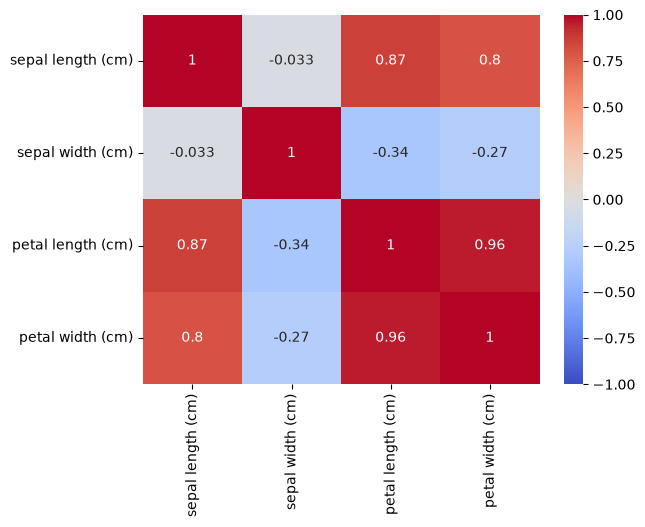

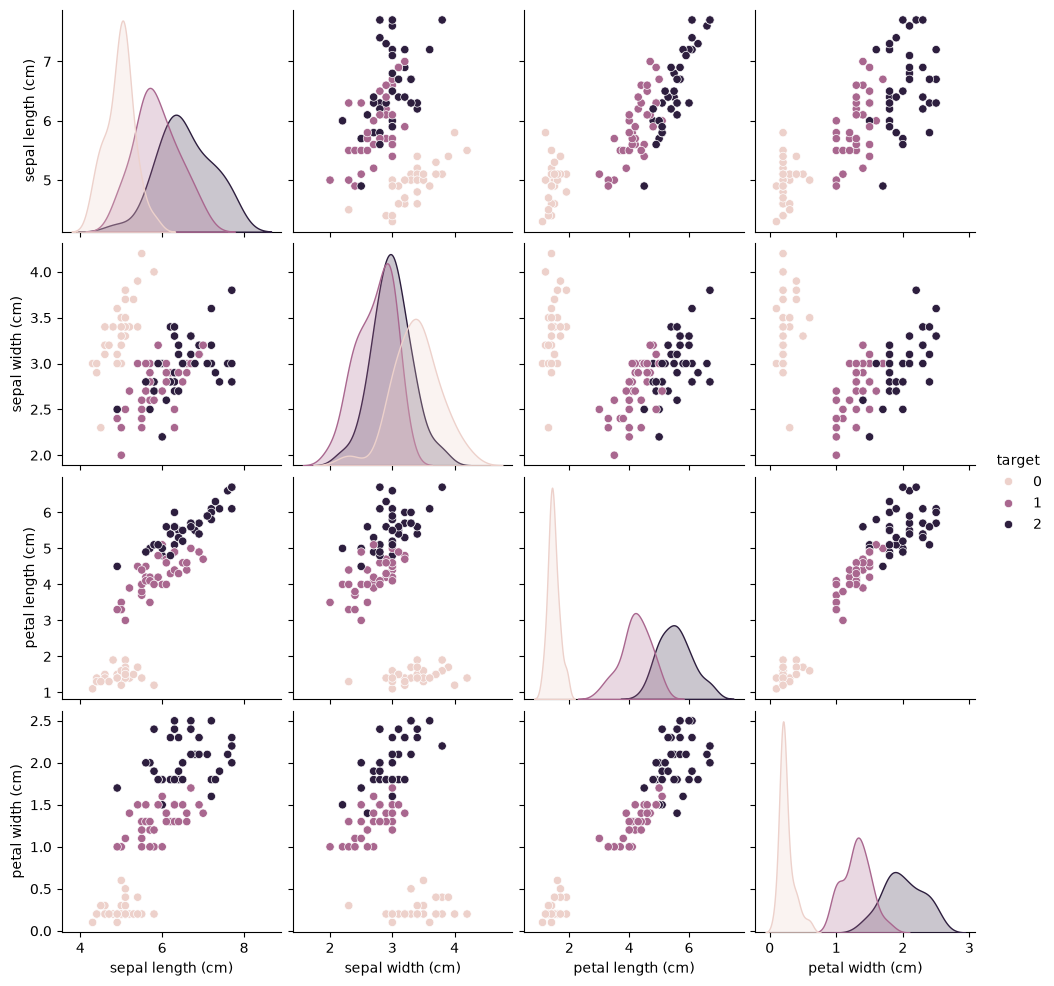

In [12]:
train_set =pd.read_csv("../train.csv")
test_set = pd.read_csv("../test.csv")

X = train_set.drop(columns=["id", "target"])
y = train_set["target"].values

sns.heatmap(X.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
sns.pairplot(train_set.drop(columns="id"), hue="target")
plt.show()




2) Train-Validation Split

In [13]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, 
    test_size= 0.2, 
    stratify = y, 
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)





3) Principal Component Analysis

In [16]:
# The first two principal components explain approximatively 95.16% of the variance in the standardized training data. 
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled) # learns the two axis of the PCA based on the training data and then maps the training data on these two axis 
X_val_pca = pca.transform(X_val_scaled) # maps the validation set onto the two axis without recomputing them 

4) Logistic Regression with Hyperparameter Tuning

In [20]:
# The initial PCA helped us choose two components, retaining approximatively 95% of the training variance. 
# During cross-validation, the pipeline refits scaling and PCA on each fold's training subset to avoid data leakage. 

model = make_pipeline(
    StandardScaler(), 
    PCA(n_components=2), 
    LogisticRegression()
)

cv = RepeatedStratifiedKFold(
    n_splits=5, 
    n_repeats=3, 
    random_state=42
)

param_grid = { 
    "logisticregression__C" : [0.01, 0.1, 1, 10, 100] # hyperparameter : regularisation term, low C = high penalty. Fixed before training, and you learn the weights. 
}

search = GridSearchCV(
    estimator=model, # the pipeline that you want to train 
    param_grid=param_grid, # different values of C that you want to compare 
    cv=cv, 
    scoring="accuracy"
)

search.fit(X_train, y_train) # starts the 75 training (5 values of C x 15 folds)

print("Best parameters:", search.best_params_)
print("Best mean CV accuracy:", search.best_score_)



Best parameters: {'logisticregression__C': 1}
Best mean CV accuracy: 0.9041666666666668


5) Evalutation 

In [21]:
y_pred = search.predict(X_val)

print("Validation accuracy:", accuracy_score(y_val, y_pred))

Validation accuracy: 0.9047619047619048


6) Logistic regression without prior PCA 

In [22]:
model_no_pca = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

search_no_pca = GridSearchCV(
    estimator=model_no_pca,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy"
)

search_no_pca.fit(X_train, y_train)

print("Best mean CV accuracy with PCA:", search.best_score_)
print("Best mean CV accuracy without PCA:", search_no_pca.best_score_)

Best mean CV accuracy with PCA: 0.9041666666666668
Best mean CV accuracy without PCA: 0.9637254901960784
